In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from src.data.data_acquire import load_df
except ModuleNotFoundError:
    from data_acquire import load_df

sns.set_theme(style="whitegrid")
df = load_df()
print(df.shape)
print(df.head())

(1840, 15)
   Id       District                                     Address Number  \
0   1  Ciudad Lineal                            Piso en Quintana    NaN   
1   2  Ciudad Lineal               Piso en calle de Arturo Soria    NaN   
2   3  Ciudad Lineal              Piso en calle de Vicente Muzas      4   
3   4  Ciudad Lineal                       Piso en calle Badajoz    NaN   
4   5  Ciudad Lineal  Piso en calle de Nuestra Señora del Villar      9   

          Area  Rent  Bedrooms  Sq.Mt  Floor  Outer  Elevator  Penthouse  \
0     Quintana  1300       2.0     72    3.0    1.0       1.0          0   
1  Costillares  3000       5.0    260    2.0    1.0       1.0          0   
2       Colina  1300       2.0    100    3.0    1.0       1.0          0   
3  San Pascual  1600       3.0    120    4.0    1.0       1.0          0   
4       Ventas   800       2.0     60    3.0    1.0       0.0          0   

   Cottage  Duplex  Semidetached  
0        0       0             0  
1        0 

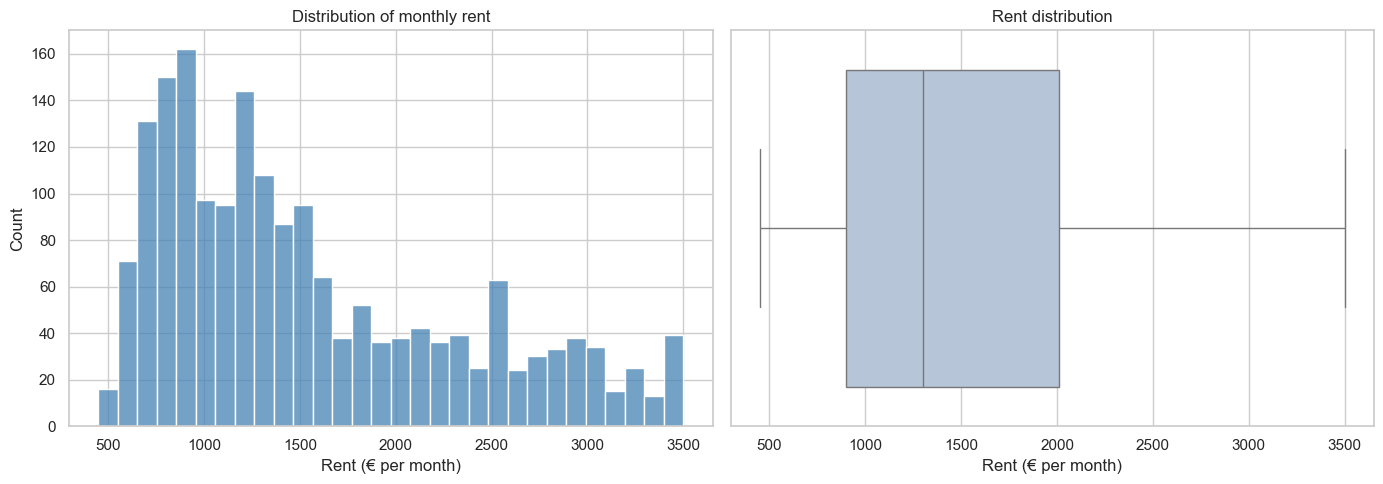

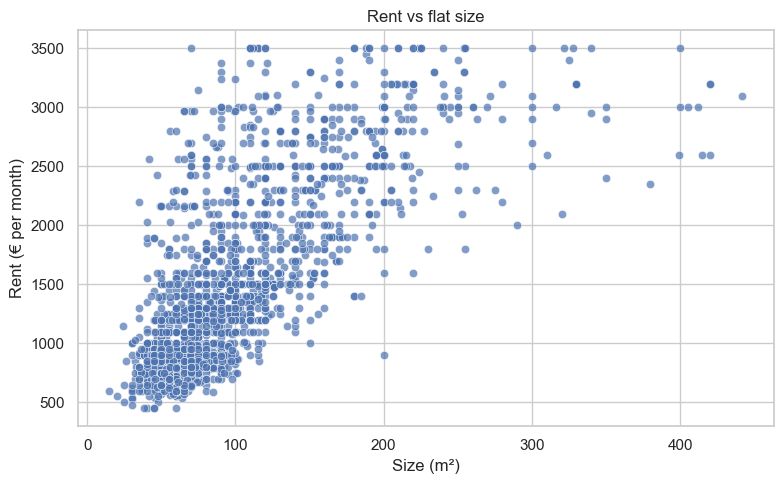

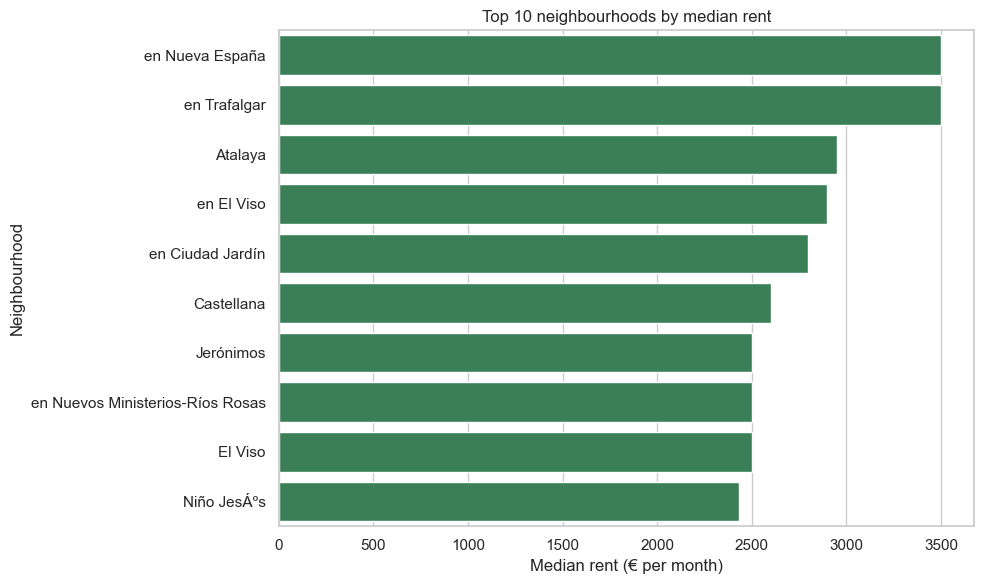

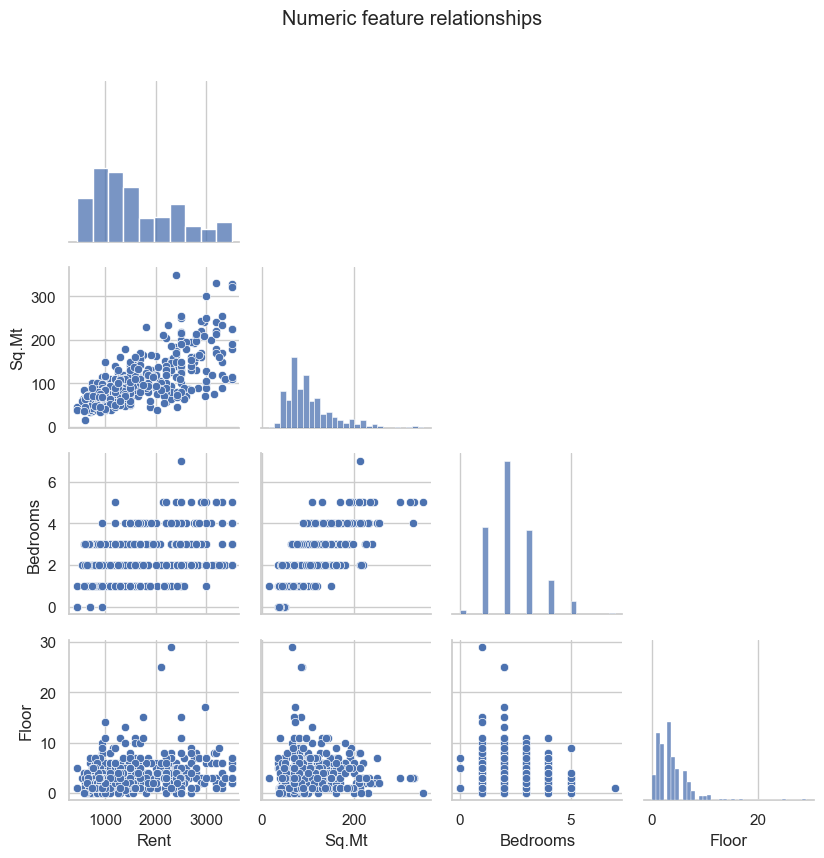

In [2]:
# Rent distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['Rent'], bins=30, ax=axes[0], color='steelblue')
axes[0].set_title('Distribution of monthly rent')
axes[0].set_xlabel('Rent (€ per month)')

sns.boxplot(x=df['Rent'], ax=axes[1], color='lightsteelblue')
axes[1].set_title('Rent distribution')
axes[1].set_xlabel('Rent (€ per month)')

plt.tight_layout()

# Rent vs size
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Sq.Mt', y='Rent', alpha=0.7)
plt.title('Rent vs flat size')
plt.xlabel('Size (m²)')
plt.ylabel('Rent (€ per month)')
plt.tight_layout()

# Neighbourhood median rent
neighbourhood_rent = (
    df.groupby('Area', dropna=False)['Rent']
    .median()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
sns.barplot(x=neighbourhood_rent.values, y=neighbourhood_rent.index, color='seagreen')
plt.title('Top 10 neighbourhoods by median rent')
plt.xlabel('Median rent (€ per month)')
plt.ylabel('Neighbourhood')
plt.tight_layout()

# Numeric summary pairwise relationships
numeric_cols = ['Rent', 'Sq.Mt', 'Bedrooms', 'Floor']
plot_df = df[numeric_cols].dropna().sample(min(len(df[numeric_cols].dropna()), 500), random_state=42)

sns.pairplot(plot_df, diag_kind='hist', corner=True, height=2.1)
plt.suptitle('Numeric feature relationships', y=1.02)
plt.tight_layout()